# Synthetic player data (modeled on Palia)

**This data is synthetic.** No game publishes player-level spending or retention data,
so this notebook generates a realistic dataset based on published industry benchmarks.

| Assumption | Value | Basis |
|---|---|---|
| Players | 50,000 installing Apr 2025 – Sep 2026 | Scaled sample |
| Install spikes | On real Palia content releases | `palia_events.csv`, sized to real Steam increases |
| D1 / D7 / D30 retention | 35% / 15% / 6% | GameAnalytics 2026 PC benchmarks (top-tier games) |
| Session length | ~40 min average | GameAnalytics PC benchmarks |
| Sessions per active day | ~1.7 | GameAnalytics PC median |
| Paying players | 3% | Konvoy (2–4%), Swrve (2.3%) |
| Top 10% of payers' revenue share | ~60% | Swrve (64%) |
| Pack prices | $4.99 – $99.99 | Palia's real price range |
| Platform and region shares | see code | Assumptions (not published for Palia) |
| Event "tourists" | 70% casual (vs 60%) for installs within 21 days of a big release | Assumption, planted to demonstrate cohort analysis |

Fixed random seed (42): re-running the notebook reproduces the same data.

In [1]:
import numpy as np
import pandas as pd

SEED = 42
N_PLAYERS = 50_000
START, END = pd.Timestamp("2025-04-01"), pd.Timestamp("2026-09-30")
rng = np.random.default_rng(SEED)

In [2]:
days = pd.date_range(START, END, freq="D")
weight = pd.Series(1.0, index=days)          # every day starts with the same base
weight[days.dayofweek >= 5] *= 1.2           # 20% more installs on weekends

# Spikes on the real content releases from palia_events.csv
events = pd.read_csv("data/palia_events.csv", parse_dates=["date"])
boost = {"2025-05-13": 3.0,   # console launch + Elderwood (Steam: +90%)
         "2025-06-12": 0.5,   # Radiance Rising (Steam: +16%)
         "2025-09-10": 0.7,   # Of Barns & Briars (Steam: +22%)
         "2026-05-12": 2.0}   # Royal Highlands (Steam: +56%)
for date, size in boost.items():
    print(date, "->", events.loc[events["date"] == date, "event"].tolist())
    days_after = (days - pd.Timestamp(date)).days
    after = days_after >= 0
    weight[after] += size * np.exp(-days_after[after] / 10)   # spike that fades over ~3 weeks

2025-05-13 -> ['PS5 and Xbox launch + Elderwood expansion']
2025-06-12 -> ['Radiance Rising update (patch 0.192)']
2025-09-10 -> ['Of Barns & Briars update (patch 0.195)']
2026-05-12 -> ['Royal Highlands expansion']


In [3]:
install_day = rng.choice(days, size=N_PLAYERS, p=(weight / weight.sum()).values)
install_time = pd.to_datetime(install_day) + pd.to_timedelta(rng.integers(0, 86400, N_PLAYERS), unit="s")

players = pd.DataFrame({"install_time": install_time}).sort_values("install_time").reset_index(drop=True)
players.insert(0, "player_id", np.arange(1, N_PLAYERS + 1))

# PlayStation and Xbox only exist from the console launch on 13 May 2025
console_live = players["install_time"] >= "2025-05-13"
players["platform"] = np.where(console_live,
    rng.choice(["PC", "Switch", "PlayStation", "Xbox"], N_PLAYERS, p=[0.45, 0.25, 0.15, 0.15]),
    rng.choice(["PC", "Switch"], N_PLAYERS, p=[0.65, 0.35]))

players["region"] = rng.choice(["North America", "Europe", "Asia", "South America", "Oceania"],
                               N_PLAYERS, p=[0.40, 0.35, 0.10, 0.08, 0.07])

# Hidden player type, used to generate behavior in the next steps (not saved in the final file).
# Assumption: players who install in the 3 weeks after a big release are more often
# casual "tourists" (70% casual instead of 60%).
BIG_RELEASES = ["2025-05-13", "2026-05-12"]
in_window = np.zeros(N_PLAYERS, dtype=bool)
for d in BIG_RELEASES:
    start = pd.Timestamp(d)
    in_window |= ((players["install_time"] >= start) &
                  (players["install_time"] < start + pd.Timedelta(days=21))).values

normal_type  = rng.choice(["casual", "regular", "core"], N_PLAYERS, p=[0.60, 0.30, 0.10])
tourist_type = rng.choice(["casual", "regular", "core"], N_PLAYERS, p=[0.70, 0.23, 0.07])
players["_type"] = np.where(in_window, tourist_type, normal_type)
print("Players in a release window:", in_window.sum())
players.head()

Players in a release window: 7101


,player_id,install_time,platform,region,_type
0,1,2025-04-01 00:18:00,PC,North America,casual
1,2,2025-04-01 00:19:18,PC,Asia,casual
2,3,2025-04-01 00:19:43,PC,North America,casual
3,4,2025-04-01 00:24:22,PC,South America,casual
4,5,2025-04-01 00:46:30,Switch,Asia,regular


platform
PC             0.463
Switch         0.258
Xbox           0.140
PlayStation    0.139
Name: proportion, dtype: float64


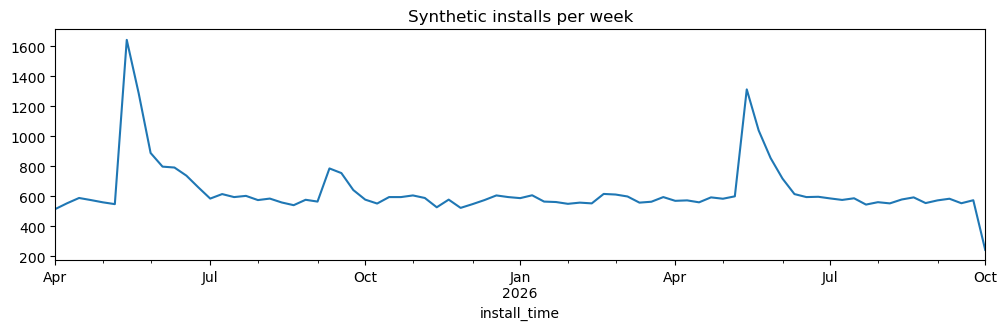

In [4]:
players.set_index("install_time").resample("W").size().plot(figsize=(12, 3), title="Synthetic installs per week")
print(players["platform"].value_counts(normalize=True).round(3))

In [5]:
TYPES = {"casual": {"lifetime": 1.5, "p_play": 0.45},
         "regular": {"lifetime": 12, "p_play": 0.55},
         "core": {"lifetime": 120, "p_play": 0.65}}

lifetime = np.zeros(N_PLAYERS)
p_play = np.zeros(N_PLAYERS)
for t, prm in TYPES.items():
    is_type = (players["_type"] == t).values
    lifetime[is_type] = rng.exponential(prm["lifetime"], is_type.sum())
    p_play[is_type] = prm["p_play"]

In [6]:
install_date = players["install_time"].dt.normalize()
days_left = (END - install_date).dt.days.values                     # data stops at END
last_day = np.minimum(np.floor(lifetime), days_left).astype(int)
n_days = last_day + 1

# One row per player per day they're still "alive" (day 0 = install day)
row_player = np.repeat(np.arange(N_PLAYERS), n_days)
day_n = np.arange(n_days.sum()) - np.repeat(np.cumsum(n_days) - n_days, n_days)

# Keep the days they actually play: always the install day, otherwise by chance
plays = (day_n == 0) | (rng.random(len(day_n)) < p_play[row_player])
row_player, day_n = row_player[plays], day_n[plays]
print("Active player-days:", len(row_player))

Active player-days: 452278


In [7]:
n_sessions = 1 + rng.poisson(0.7, len(row_player))       # 1.7 sessions per active day on average
s_player = np.repeat(row_player, n_sessions)
s_day = np.repeat(day_n, n_sessions)

# Start times: more sessions in the evening, few at night
hours = np.arange(24)
hour_weight = np.where(hours >= 17, 3.0, np.where(hours >= 8, 1.5, 0.4))
hour_weight = hour_weight / hour_weight.sum()
session_start = (install_date.values[s_player]
                 + pd.to_timedelta(s_day, unit="D").values
                 + pd.to_timedelta(rng.choice(hours, len(s_player), p=hour_weight) * 3600
                                   + rng.integers(0, 3600, len(s_player)), unit="s").values)
session_start = np.maximum(session_start, players["install_time"].values[s_player])  # never before install

sessions = pd.DataFrame({
    "player_id": players["player_id"].values[s_player],
    "session_start": session_start,
    "duration_minutes": np.round(rng.lognormal(np.log(40) - 0.32, 0.8, len(s_player)), 1),
}).sort_values(["player_id", "session_start"]).reset_index(drop=True)
print("Sessions:", len(sessions))

Sessions: 768420


In [8]:
s = sessions.merge(players[["player_id", "install_time"]], on="player_id")
s["day_n"] = (s["session_start"].dt.normalize() - s["install_time"].dt.normalize()).dt.days

for n, target in [(1, 0.35), (7, 0.15), (30, 0.06)]:
    eligible = (END - players["install_time"].dt.normalize()).dt.days >= n
    retained = s.loc[s["day_n"] == n, "player_id"].nunique() / eligible.sum()
    print(f"D{n} retention: {retained:.1%}   (target {target:.0%})")

print("Average session:", round(sessions["duration_minutes"].mean(), 1), "min | median:", sessions["duration_minutes"].median(), "min")
print("Sessions per active day:", round(s.groupby(["player_id", "day_n"]).size().mean(), 2))

D1 retention: 35.4%   (target 35%)
D7 retention: 14.9%   (target 15%)
D30 retention: 6.2%   (target 6%)
Average session: 40.0 min | median: 29.1 min
Sessions per active day: 1.7


In [9]:
  print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.3.5 | pandas 2.3.3


In [10]:
PAY_CHANCE = {"casual": 0.005, "regular": 0.03, "core": 0.18}
is_payer = rng.random(N_PLAYERS) < players["_type"].map(PAY_CHANCE).values

spend_level = rng.lognormal(0, 0.8, N_PLAYERS)                 # personal spending intensity: most low, a few very high
active_days = np.bincount(row_player, minlength=N_PLAYERS)     # how many days each player played
n_purchases = np.where(is_payer, 1 + rng.poisson(spend_level * np.sqrt(active_days) * 0.4), 0)
print("Payers:", is_payer.sum(), f"({is_payer.mean():.1%}) | purchases:", n_purchases.sum())

Payers: 1446 (2.9%) | purchases: 5574


In [11]:
# Spender tier among payers: top 10% = "big", next 20% = "medium", rest = "small"
pct = pd.Series(spend_level[is_payer]).rank(pct=True).values
tier = np.full(N_PLAYERS, "", dtype=object)
tier[is_payer] = np.where(pct > 0.9, "big", np.where(pct > 0.7, "medium", "small"))

PACKS = [4.99, 9.99, 19.99, 49.99, 99.99]
PACK_CHANCE = {"small":  [0.55, 0.30, 0.10, 0.04, 0.01],
               "medium": [0.30, 0.30, 0.25, 0.10, 0.05],
               "big":    [0.10, 0.15, 0.25, 0.25, 0.25]}

buyer = np.repeat(np.arange(N_PLAYERS), n_purchases)          # one row per purchase
amount = np.empty(len(buyer))
for t, p in PACK_CHANCE.items():
    m = tier[buyer] == t
    amount[m] = rng.choice(PACKS, m.sum(), p=p)

In [12]:
pid = sessions["player_id"].values
first_session = np.searchsorted(pid, players["player_id"].values[buyer])   # where each buyer's sessions start
sessions_count = np.bincount(pid - 1, minlength=N_PLAYERS)[buyer]
chosen = first_session + (rng.random(len(buyer)) * sessions_count).astype(int)  # a random session of that buyer
offset_sec = rng.random(len(buyer)) * sessions["duration_minutes"].values[chosen] * 60

purchases = pd.DataFrame({
    "player_id": players["player_id"].values[buyer],
    "purchase_time": sessions["session_start"].values[chosen] + pd.to_timedelta(offset_sec, unit="s").values,
    "amount_usd": amount,
}).sort_values(["player_id", "purchase_time"]).reset_index(drop=True)
print("Purchases table:", len(purchases), "rows")

Purchases table: 5574 rows


In [13]:
revenue = purchases.groupby("player_id")["amount_usd"].sum().sort_values(ascending=False)
top10_share = revenue.head(int(len(revenue) * 0.10)).sum() / revenue.sum()

print(f"Paying players: {len(revenue) / N_PLAYERS:.1%}   (target 3%)")
print(f"Top 10% of payers' share of revenue: {top10_share:.0%}   (target ~60%)")
print(f"Total revenue: ${revenue.sum():,.0f} | ARPPU: ${revenue.mean():.0f} | median payer: ${revenue.median():.0f} | biggest payer: ${revenue.max():,.0f}")
print(purchases["amount_usd"].value_counts(normalize=True).sort_index().round(2))

Paying players: 2.9%   (target 3%)
Top 10% of payers' share of revenue: 61%   (target ~60%)
Total revenue: $125,164 | ARPPU: $87 | median payer: $25 | biggest payer: $3,014
amount_usd
4.99     0.36
9.99     0.26
19.99    0.19
49.99    0.11
99.99    0.09
Name: proportion, dtype: float64


In [14]:
s_chk = sessions.merge(players[["player_id", "install_time"]], on="player_id")
p_chk = purchases.merge(players[["player_id", "install_time"]], on="player_id")

print("Sessions before install: ", (s_chk["session_start"] < s_chk["install_time"]).sum())
print("Purchases before install:", (p_chk["purchase_time"] < p_chk["install_time"]).sum())
print("Players without any session:", (~players["player_id"].isin(sessions["player_id"])).sum())
print("Sessions from", sessions["session_start"].min().date(), "to", sessions["session_start"].max().date())
print("Rows -> players:", len(players), "| sessions:", len(sessions), "| purchases:", len(purchases))

Sessions before install:  0
Purchases before install: 0
Players without any session: 0
Sessions from 2025-04-01 to 2026-09-30
Rows -> players: 50000 | sessions: 768420 | purchases: 5574


In [15]:
import os
os.makedirs("data/synthetic", exist_ok=True)

players.drop(columns="_type").to_csv("data/synthetic/synthetic_players.csv", index=False)
sessions.to_csv("data/synthetic/synthetic_sessions.csv", index=False)
purchases.to_csv("data/synthetic/synthetic_purchases.csv", index=False)

# The hidden player types, saved separately: an "answer key" for checking your segmentation later
players[["player_id", "_type"]].rename(columns={"_type": "true_type"}) \
    .to_csv("data/synthetic/answer_key_player_types.csv", index=False)
print("Saved 4 files to data/synthetic/")

Saved 4 files to data/synthetic/
